# EDA: MT-Bench human judgments

Exploratory look at expert pairwise judgments from MT-Bench: for each question, a human compared the answers of two models and picked the better one (or a tie). This is the data the LLM judge will be calibrated against.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

DATASET_NAME = "lmsys/mt_bench_human_judgments"
SPLIT = "human"
TOP_N_PAIRS = 10

/Users/patrykczechowski/studia/llm-eval/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the data

In [2]:
ds = load_dataset(DATASET_NAME, split=SPLIT)
df = ds.to_pandas()
assert isinstance(df, pd.DataFrame)  # narrows the union type for Pylance

print(f"Rows: {len(df)}, columns: {len(df.columns)}")
print(f"Columns: {list(df.columns)}")

Rows: 3355, columns: 8
Columns: ['question_id', 'model_a', 'model_b', 'winner', 'judge', 'conversation_a', 'conversation_b', 'turn']


In [3]:
df.iloc[0]

question_id                                                      81
model_a                                                  alpaca-13b
model_b                                               gpt-3.5-turbo
winner                                                      model_b
judge                                                      author_2
conversation_a    [{'content': 'Compose an engaging travel blog ...
conversation_b    [{'content': 'Compose an engaging travel blog ...
turn                                                              1
Name: 0, dtype: object

## 2. Verdict distribution

In [4]:
verdict_counts = df["winner"].value_counts()
verdicts = pd.DataFrame(
    {
        "count": verdict_counts,
        "percent": (verdict_counts / len(df) * 100).round(1),
    }
)

print(
    f"Ties: {verdicts.loc['tie', 'count']} of {len(df)} ({verdicts.loc['tie', 'percent']}%)"
)
verdicts

Ties: 780 of 3355 (23.2%)


,count,percent
winner,,
model_a,1293,38.5
model_b,1282,38.2
tie,780,23.2


## 3. Most frequent model pairs

In [5]:
pair_counts = df.groupby(["model_a", "model_b"]).size()
top_pairs = pair_counts.nlargest(TOP_N_PAIRS)
top_pairs

model_a          model_b        
gpt-3.5-turbo    vicuna-13b-v1.2    182
vicuna-13b-v1.2  gpt-3.5-turbo      179
gpt-3.5-turbo    alpaca-13b         168
                 claude-v1          157
                 gpt-4              153
alpaca-13b       gpt-3.5-turbo      150
llama-13b        gpt-3.5-turbo      141
gpt-3.5-turbo    llama-13b          131
gpt-4            gpt-3.5-turbo      126
                 claude-v1          120
dtype: int64

## 4. Verdict distribution chart

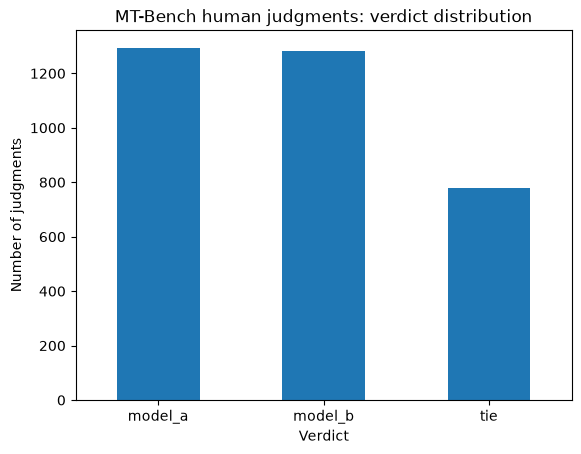

In [6]:
ax = verdicts["count"].plot.bar(rot=0)
ax.set_title("MT-Bench human judgments: verdict distribution")
ax.set_xlabel("Verdict")
ax.set_ylabel("Number of judgments")
plt.show()

## Observations

1. **No position bias among experts.** `model_a` wins 38.5% and `model_b` 38.2% of judgments, so the order in which answers were shown barely affects the verdict. An LLM judge calibrated on this data should be checked for the same property, because LLM judges are known to prefer the first answer.
2. **Ties are a real outcome, not noise.** 23.2% of judgments (780 of 3355) are ties, so the judge must be able to return `tie`; a judge forced to always pick a winner would be wrong on roughly one in four cases by design.
3. **The data is unbalanced around `gpt-3.5-turbo`.** It appears in 44% of all rows and in 9 of the 10 most frequent pairs, while every pair occurs in both orders (e.g. vs `vicuna-13b-v1.2`: 182 + 179). Agreement measured on this set will mostly reflect how well the judge handles comparisons against `gpt-3.5-turbo`, so per-pair metrics are worth reporting separately.
